#### Objective
1. Make the learner load the data using pandas.
2. Create new columns in dataset from existing columns.
3. Use pandas to answer questions of interest.
4. Plot variables of interest.
##### Dataset used: Prisoners dataset sourced from data.gov.in

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.style.use('default')

In [5]:
prisoner_df = pd.read_csv('./files/prisoners.csv')
prisoner_df

,STATE/UT,YEAR,No. of Inmates benefitted by Elementary Education,No. of Inmates benefitted by Adult Education,No. of Inmates benefitted by Higher Education,No. of Inmates benefitted by Computer Course
0,Andhra Pradesh,2013,9480,13758,672,170
1,Arunachal Pradesh,2013,0,0,0,0
2,Assam,2013,676,750,14,30
3,Bihar,2013,1693,3013,125,1417
4,Chhatisgarh,2013,1664,1803,192,103
5,Goa,2013,7,0,6,88
6,Gujarat,2013,2310,3133,875,966
7,Haryana,2013,1131,774,1112,243
8,Himachal Pradesh,2013,33,80,26,0
9,Jammu & Kashmir,2013,102,124,33,34


In [6]:
# a. Load the dataset “prisoners.csv” using pandas and display the first and last five rows in the dataset.
prisoner_df.head(5)

,STATE/UT,YEAR,No. of Inmates benefitted by Elementary Education,No. of Inmates benefitted by Adult Education,No. of Inmates benefitted by Higher Education,No. of Inmates benefitted by Computer Course
0,Andhra Pradesh,2013,9480,13758,672,170
1,Arunachal Pradesh,2013,0,0,0,0
2,Assam,2013,676,750,14,30
3,Bihar,2013,1693,3013,125,1417
4,Chhatisgarh,2013,1664,1803,192,103


In [7]:
prisoner_df.tail(5)

,STATE/UT,YEAR,No. of Inmates benefitted by Elementary Education,No. of Inmates benefitted by Adult Education,No. of Inmates benefitted by Higher Education,No. of Inmates benefitted by Computer Course
30,D & N Haveli,2013,0,0,0,0
31,Daman & Diu,2013,0,0,0,0
32,Delhi,2013,1458,1187,908,174
33,Lakshadweep,2013,0,0,0,0
34,Pondicherry,2013,0,0,0,0


In [8]:
# Use describe method in pandas and find out the number of columns. Can you say something about those rows who have zero inmates?
#prisoner_df.info()
prisoner_df.describe()

,YEAR,No. of Inmates benefitted by Elementary Education,No. of Inmates benefitted by Adult Education,No. of Inmates benefitted by Higher Education,No. of Inmates benefitted by Computer Course
count,35.0,35.000000,35.000000,35.000000,35.000000
mean,2013.0,1057.914286,1534.857143,237.457143,210.171429
std,0.0,2078.196777,3022.110503,375.614191,359.117340
min,2013.0,0.000000,0.000000,0.000000,0.000000
25%,2013.0,0.000000,6.500000,2.000000,0.000000
50%,2013.0,167.000000,237.000000,33.000000,38.000000
75%,2013.0,1294.500000,1733.500000,234.500000,227.500000
max,2013.0,9480.000000,13758.000000,1353.000000,1417.000000


In [9]:
# Create a new column -’total_benefitted’ that is a sum of inmates benefitted through all modes.
prisoner_df['total_benefitted'] = prisoner_df.iloc[:,2:6].sum(axis=1)
prisoner_df

,STATE/UT,YEAR,No. of Inmates benefitted by Elementary Education,No. of Inmates benefitted by Adult Education,No. of Inmates benefitted by Higher Education,No. of Inmates benefitted by Computer Course,total_benefitted
0,Andhra Pradesh,2013,9480,13758,672,170,24080
1,Arunachal Pradesh,2013,0,0,0,0,0
2,Assam,2013,676,750,14,30,1470
3,Bihar,2013,1693,3013,125,1417,6248
4,Chhatisgarh,2013,1664,1803,192,103,3762
5,Goa,2013,7,0,6,88,101
6,Gujarat,2013,2310,3133,875,966,7284
7,Haryana,2013,1131,774,1112,243,3260
8,Himachal Pradesh,2013,33,80,26,0,139
9,Jammu & Kashmir,2013,102,124,33,34,293


In [10]:
# Create a new row -“totals” that is the sum of all inmates benefitted through each mode across all states.
total_df =prisoner_df.iloc[:,:].sum().to_frame().T
total_df['YEAR'] = ""
total_df['STATE/UT'] = 'Total'
total_df

,STATE/UT,YEAR,No. of Inmates benefitted by Elementary Education,No. of Inmates benefitted by Adult Education,No. of Inmates benefitted by Higher Education,No. of Inmates benefitted by Computer Course,total_benefitted
0,Total,,37027,53720,8311,7356,106414


In [11]:
prisoner_df = pd.concat([prisoner_df,total_df],ignore_index=True)

In [12]:
prisoner_df.tail(3)

,STATE/UT,YEAR,No. of Inmates benefitted by Elementary Education,No. of Inmates benefitted by Adult Education,No. of Inmates benefitted by Higher Education,No. of Inmates benefitted by Computer Course,total_benefitted
33,Lakshadweep,2013,0,0,0,0,0
34,Pondicherry,2013,0,0,0,0,0
35,Total,,37027,53720,8311,7356,106414


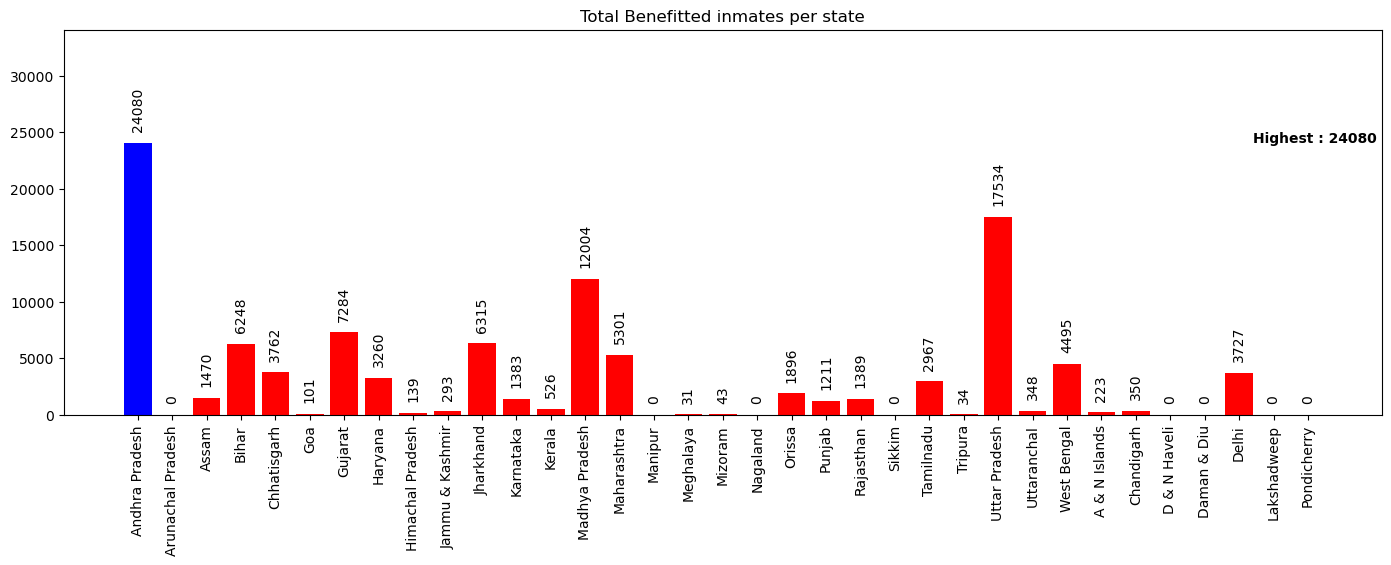

In [13]:
# Make a bar plot with each state name on the x -axis and their total benefitted inmates as their bar heights.
# Which state has the maximum number of beneficiaries?
plt.figure(figsize=(17,5))
bars = plt.bar(prisoner_df['STATE/UT'][:-1],prisoner_df['total_benefitted'][:-1],color='red')
plt.bar(prisoner_df[prisoner_df['total_benefitted'] == max(prisoner_df['total_benefitted'][:-1])]['STATE/UT'],max(prisoner_df['total_benefitted'][:-1]),color='blue')
plt.text(bars[-8].get_width()+bars[-3].get_x(),bars[0].get_height(),f"Highest : {bars[0].get_height()}",fontweight='bold')
plt.xticks(rotation=90)
for bar in bars:
    plt.text(x=bar.get_x()+bar.get_width()/2,y=bar.get_height()+1000,s=bar.get_height(),ha='center',va='bottom',rotation='vertical')
plt.ylim(0,max(prisoner_df['total_benefitted'][:-1])+10000)
plt.title("Total Benefitted inmates per state")
plt.show()

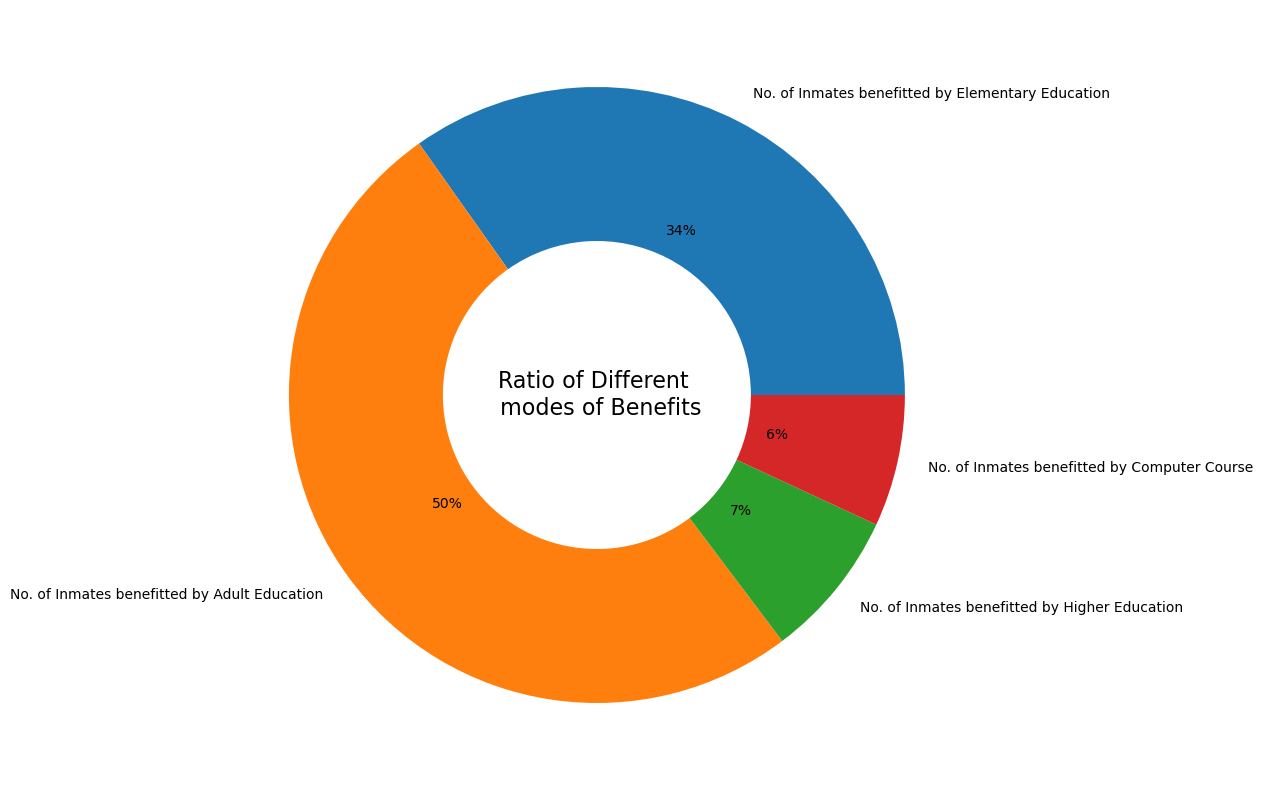

In [63]:
# Make a pie chart that depicts the ratio among different modes of benefits.

plt.figure(figsize=(17,10))
plt.pie(prisoner_df.iloc[-1].values[2:6],autopct='%d%%',labels=prisoner_df.columns[2:6],wedgeprops=dict(width=0.5))
plt.text(0,0,"Ratio of Different \n modes of Benefits",ha='center',va='center',fontsize=16)
plt.show()